In [1]:
# Pre-import and set for a clear ploting
from matplotlib import pyplot as plt
plt.rcParams['figure.dpi'] = 60
plt.rcParams['font.size'] = 10
plt.rcParams['figure.figsize'] = (24, 6)
from utils.datasets import mani_dataset # special Dataset class

In [3]:
import cv2
import os

# 定义文件夹路径
input_folder = '/root/IML-ViT-main/IML-ViT-main/imagesFromFE/Tp'
output_folder = '/root/IML-ViT-main/IML-ViT-main/imagesFromFE/Gt'

# 确保输出文件夹存在
os.makedirs(output_folder, exist_ok=True)

# 遍历输入文件夹中的所有图片文件
for filename in os.listdir(input_folder):
    # 构建输入和输出文件路径
    input_path = os.path.join(input_folder, filename)
    output_path = os.path.join(output_folder, filename)
    #print(input_path)
    #print(output_path)
    # 读取彩色图像
    image = cv2.imread(input_path)

    # 将彩色图像转换为灰度图像
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # 保存灰度图像
    cv2.imwrite(output_path, gray)

In [4]:
# here we use mani dataset as example
input_dir = "./imagesFromFE/"
dataset = mani_dataset(
    path = input_dir,
    edge_width=7, # specify the edge mask, other wise only return 2 objects
    if_return_shape=True
)
print(dataset)
print("len:", len(dataset))

len: 1


In [5]:
#加载权重信息
import torch
from iml_vit_model import iml_vit_model

# Check if GPU is available
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu' # if out of memory, then uncommenting this line
#print("?:",torch.cuda.is_available())
print("Device:", device)
#print("PyTorch 版本:", torch.__version__)
ckpt_path = "./checkpoints/iml-vit_checkpoint.pth"
model = iml_vit_model()

model.load_state_dict(
    torch.load(ckpt_path),
    strict = False
)
model = model.to(device)

Device: cuda


In [6]:
model.eval()
outputs=[]
with torch.no_grad():
    for img, gt, edge_mask, shape in dataset:    # Inference don't need edge mask.
        img, gt,edge_mask = img.to(device), gt.to(device),edge_mask.to(device)
        # Since no Dataloader, manually create a Batch with size==1
        img = img.unsqueeze(0) # CHW -> 1CHW
        gt = gt.unsqueeze(0)
        edge_mask = edge_mask.unsqueeze(0)
        print("shape:", shape)
        # inference 使用模型执行测试图片
        predict_loss, mask_pred,edge_loss = model(img, gt, edge_mask)
        #print(f"Predict Loss:{predict_loss}, including edge loss: {edge_loss}")
        output = mask_pred
        #print(output)
        # Cut the origin area from padded image
        output = output[0, :, 0:shape[0], 0:shape[1]].permute(1, 2, 0).cpu().numpy()
        outputs.append(output)
        '''
        plt.title("Cropped region")
        plt.imshow(output, cmap='gray')
        plt.axis(False)
        plt.show()  # 显示图像
        '''
#print("Done!")

shape: tensor([384, 256])


In [7]:
import cv2
import numpy as np
import sys
from PIL import Image
if len(outputs)==0:
    print('无待检测图片')
    sys.exit()
# 这里只针对单张图片进行检测
output=outputs[0]
output_uint8 = (output * 255).astype('uint8')
#print(output_uint8.dtype)
_, binary_image = cv2.threshold(output_uint8, 255*0.3, 255, cv2.THRESH_BINARY)
kernel = np.ones((3,3), np.uint8)
cleaned_image = cv2.morphologyEx(binary_image, cv2.MORPH_OPEN, kernel)
# 将cv2的bgr格式转为rgb格式的图片
cleaned_image_rgb = cv2.cvtColor(cleaned_image, cv2.COLOR_BGR2RGB)

'''
# 创建PIL图像对象
pil_image = Image.fromarray(cleaned_image_rgb)
# 保存图像到指定路径
save_path = '/root/IML-ViT-main/IML-ViT-main/imagesFromFE/01.jpg'
pil_image.save(save_path)
plt.imshow(cleaned_image_rgb)
plt.show()
'''

"\n# 创建PIL图像对象\npil_image = Image.fromarray(cleaned_image_rgb)\n# 保存图像到指定路径\nsave_path = '/root/IML-ViT-main/IML-ViT-main/imagesFromFE/01.jpg'\npil_image.save(save_path)\nplt.imshow(cleaned_image_rgb)\nplt.show()\n"

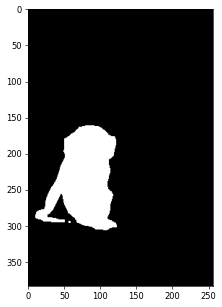

In [8]:
# 多个mask仅保留面积最大的mask
import cv2
import numpy as np

# 寻找轮廓
contours, _ = cv2.findContours(cleaned_image, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 找到最大面积的轮廓
max_area = 0
max_contour = None
for contour in contours:
    area = cv2.contourArea(contour)
    if area > max_area:
        max_area = area
        max_contour = contour

# 创建掩膜图像，将最大面积的轮廓填充为白色，其余区域填充为黑色
mask = np.zeros_like(image)
cv2.drawContours(mask, [max_contour], 0, 255, -1)

# 将掩膜应用于原图像，将小白色图块填充为黑色
result = cv2.bitwise_and(image, mask)

# 将cv2的bgr格式转为rgb格式的图片
cleaned_image_rgb = cv2.cvtColor(cleaned_image, cv2.COLOR_BGR2RGB)

# 创建PIL图像对象
pil_image = Image.fromarray(cleaned_image_rgb)
# 保存图像到指定路径
save_path = '/root/IML-ViT-main/IML-ViT-main/maskResults/mask.jpg'
pil_image.save(save_path)

plt.imshow(cleaned_image_rgb)
plt.show()